# SecureMed AI
## 1. Project Introduction
Pneumonia classification with secure image storage and transmission. Educational prototype; not clinically validated. Fictional identities only.
## 2. Original Problem Statement
Develop an AI-based system to detect diseases from medical images while ensuring secure storage and transmission of patient data.
## 3. Objectives
Train and evaluate a custom CNN, encrypt sensitive fields, enforce record permissions and verify local TLS.
## 4. System Architecture
X-ray â†’ preprocessing â†’ CNN â†’ AES-GCM â†’ SQLite. Login â†’ Argon2id â†’ authorization â†’ in-memory decryption. Loopback TLS separately transports an encrypted payload.
Run all cells with the project .venv. Shared security/database functions are imported from the application to avoid competing implementations. Training and experiments live only here.
## 5. Environment and GPU Detection

**Website update:** The user interface is now React + FastAPI. The standalone security experiments below retain the earlier doctor-assignment design in isolated temporary databases for research reproducibility. The website uses patient-owned records, one administrator, and backend-managed keys. Shared inference is in `research_support.py`; no Streamlit installation is needed. Run the website using the root `start.ps1`.

In [1]:
import os,sys,time,json,random,hashlib,re,io,tempfile,secrets,ast,inspect
from pathlib import Path
sys.dont_write_bytecode=True
os.environ['PYTHONDONTWRITEBYTECODE']='1'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import Dataset,DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,classification_report,RocCurveDisplay
from IPython.display import display
BASE=Path.cwd() if Path('research_support.py').exists() else Path.cwd()/'SecureMed_AI'
sys.path.insert(0,str(BASE))
import research_support as app
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4,os.cpu_count() or 1))
device=torch.device('cuda' if torch.cuda.is_available() else 'mps' if hasattr(torch.backends,'mps') and torch.backends.mps.is_available() else 'cpu')
if device.type=='cuda':
    torch.cuda.manual_seed_all(SEED); torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
print({'python':sys.version.split()[0],'torch':str(torch.__version__),'device':str(device),'cuda_available':torch.cuda.is_available(),'cuda_build':torch.version.cuda})
if device.type=='cuda': print(torch.cuda.get_device_name(),'free/total bytes:',torch.cuda.mem_get_info())
else: print('CPU/MPS fallback. NVIDIA installation guidance: https://pytorch.org/get-started/locally/')

{'python': '3.13.11', 'torch': '2.8.0+cu128', 'device': 'cuda', 'cuda_available': True, 'cuda_build': '12.8'}
NVIDIA GeForce RTX 3050 6GB Laptop GPU free/total bytes: (5404360704, 6441926656)


## 6. Dataset Loading
Source: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia . Detect existing ../archive/chest_xray without moving files. Alternatively place chest_xray/{train,val,test}/{NORMAL,PNEUMONIA} beside this notebook or set SECUREMED_DATASET.
Optional PowerShell download: `python -m pip install kaggle`, then `kaggle datasets download -d paultimothymooney/chest-xray-pneumonia --unzip -p chest_xray`. Configure credentials privately; never paste them into cells.


In [2]:
candidates=[Path(os.environ['SECUREMED_DATASET'])] if os.environ.get('SECUREMED_DATASET') else []
candidates += [BASE/'chest_xray',BASE/'chest_xray/chest_xray',BASE.parent/'archive/chest_xray',BASE.parent/'archive/chest_xray/chest_xray']
data_root=next((p for p in candidates if all((p/s/c).is_dir() for s in ['train','val','test'] for c in app.CLASS_MAP)),None)
if data_root is None: raise FileNotFoundError('Place or download the Kaggle dataset as described above.')
rows=[]; unreadable=[]
for split in ['train','val','test']:
    for label,target in app.CLASS_MAP.items():
        for path in sorted((data_root/split/label).iterdir()):
            if path.suffix.lower() not in {'.jpeg','.jpg','.png'}: continue
            try:
                raw=path.read_bytes()
                with Image.open(io.BytesIO(raw)) as im: size=im.size; im.verify()
                match=re.match(r'(person\d+|IM-\d+|NORMAL2-IM-\d+)',path.stem)
                rows.append(dict(path=str(path),split=split,label=label,target=target,width=size[0],height=size[1],sha256=hashlib.sha256(raw).hexdigest(),patient=match.group(1) if match else 'unknown:'+path.name,patient_known=match is not None))
            except Exception as e: unreadable.append({'path':str(path),'error':type(e).__name__})
frame=pd.DataFrame(rows); assert not frame.empty
print('Dataset:',data_root)
display(frame.groupby(['split','label']).size().unstack(fill_value=0))
print('Unreadable:',len(unreadable))
if unreadable: display(pd.DataFrame(unreadable))

Dataset: D:\SEM_5\ISC\ISC_PROJECT\archive\chest_xray


label,NORMAL,PNEUMONIA
split,,
test,234,390
train,1341,3875
val,8,8


Unreadable: 0


## 7. Exploratory Data Analysis

,width,height
count,5856.000000,5856.000000
mean,1327.880806,970.689037
std,363.500922,383.392117
min,384.000000,127.000000
25%,1056.000000,688.000000
50%,1281.000000,888.000000
75%,1560.000000,1187.000000
max,2916.000000,2713.000000


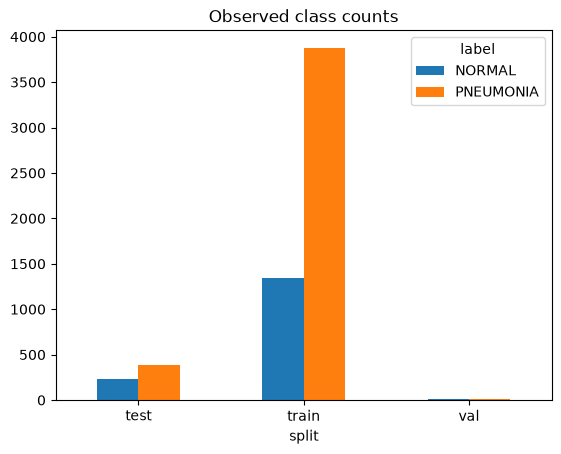

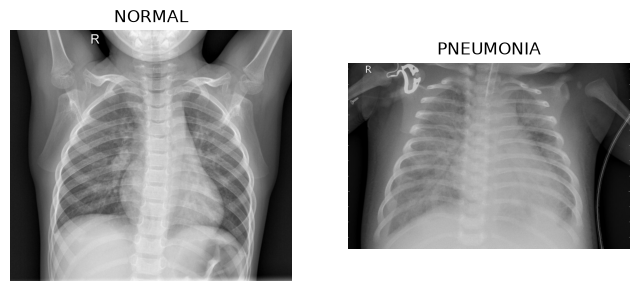

In [3]:
display(frame[['width','height']].describe())
frame.groupby(['split','label']).size().unstack().plot.bar(title='Observed class counts',rot=0); plt.show()
fig,axes=plt.subplots(1,2,figsize=(8,4))
for ax,label in zip(axes,app.CLASS_MAP):
    with Image.open(frame[frame.label==label].iloc[0].path) as im: ax.imshow(im,cmap='gray')
    ax.set_title(label); ax.axis('off')
plt.show()

## 8. Dataset Cleaning and Leakage Checks
Keep original test unchanged. Exclude training files sharing exact hashes or filename-derived patient IDs with test. Audit but do not tune on the tiny original validation set. Remove training duplicates and split patient groups with stratification. These IDs are proxies: independently verified patient independence cannot be established. Report within-test duplicates without silently deleting them.


In [3]:
test_df=frame[frame.split=='test'].copy(); pool=frame[frame.split=='train'].copy()
print('Duplicate occurrences:',int(frame.duplicated('sha256').sum()),'within test:',int(test_df.duplicated('sha256').sum()))
print('Unknown patient IDs:',int((~frame.patient_known).sum()))
for a,b in [('train','test'),('train','val'),('val','test')]:
    aa,bb=frame[frame.split==a],frame[frame.split==b]
    print(a,b,'shared hashes',len(set(aa.sha256)&set(bb.sha256)),'shared filename IDs',len(set(aa.patient)&set(bb.patient)))
excluded=pool.sha256.isin(test_df.sha256)|pool.patient.isin(test_df.patient)
print('Training exclusions for test overlap:',int(excluded.sum()))
pool=pool[~excluded].copy()
# Merge patients connected by exact hashes before deduplication.
parent={p:p for p in pool.patient.unique()}
def find(p):
    while parent[p]!=p: parent[p]=parent[parent[p]]; p=parent[p]
    return p
for _,group in pool.groupby('sha256'):
    ids=group.patient.tolist()
    for p in ids[1:]: parent[find(p)]=find(ids[0])
pool['group']=pool.patient.map(find)
pool=pool.drop_duplicates('sha256').reset_index(drop=True)
tr,va=next(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED).split(pool,pool.target,pool.group))
train_df,val_df=pool.iloc[tr].copy(),pool.iloc[va].copy()
assert not set(train_df.sha256)&set(val_df.sha256)
assert not set(train_df.patient)&set(val_df.patient)
assert not set(pool.sha256)&set(test_df.sha256)
assert not set(pool.patient)&set(test_df.patient)
for name,df in [('train',train_df),('validation',val_df),('test',test_df)]: print(name,len(df),df.label.value_counts().to_dict())
manifest_digest=hashlib.sha256('\n'.join(sorted(f'{r.split}:{r.sha256}' for r in frame.itertuples())).encode()).hexdigest()

Duplicate occurrences: 32 within test: 6
Unknown patient IDs: 0
train test shared hashes 0 shared filename IDs 170
train val shared hashes 0 shared filename IDs 0


val test shared hashes 0 shared filename IDs 0
Training exclusions for test overlap: 457


train 3790 {'PNEUMONIA': 2718, 'NORMAL': 1072}
validation 947 {'PNEUMONIA': 679, 'NORMAL': 268}
test 624 {'PNEUMONIA': 390, 'NORMAL': 234}


## 9. Image Preprocessing
RGB, 224Ã—224, tensor scaled to [0,1], channel means/stds of 0.5. Evaluation and application use identical preprocessing.
## 10. Data Augmentation
Small rotations, translations and zoom. No flips because chest laterality can matter.


In [4]:
eval_transform=app.preprocessing()
train_transform=transforms.Compose([transforms.Resize((224,224)),transforms.RandomAffine(7,translate=(0.03,0.03),scale=(0.95,1.05)),transforms.ToTensor(),transforms.Normalize(app.MEAN,app.STD)])
class XrayDataset(Dataset):
    def __init__(self,df,transform): self.rows=df.reset_index(drop=True); self.transform=transform; self.cache={}
    def __len__(self): return len(self.rows)
    def __getitem__(self,index):
        row=self.rows.iloc[index]
        if index not in self.cache:
            with Image.open(row.path) as image: self.cache[index]=transforms.Resize((224,224))(image.convert('RGB'))
        x=self.transform(self.cache[index])
        return x,torch.tensor(float(row.target),dtype=torch.float32)

## 11. PyTorch DataLoaders
Resized images are cached in RAM on first use (roughly 0.9 GB for this dataset), reducing repeated disk reads. No cache files are created.


In [6]:
BATCH_SIZE=32 if device.type=='cuda' else 16
# Zero workers avoids Windows spawning of notebook-defined classes.
generator=torch.Generator().manual_seed(SEED)
train_loader=DataLoader(XrayDataset(train_df,train_transform),batch_size=BATCH_SIZE,shuffle=True,num_workers=0,pin_memory=device.type=='cuda',generator=generator)
val_loader=DataLoader(XrayDataset(val_df,eval_transform),batch_size=BATCH_SIZE,num_workers=0,pin_memory=device.type=='cuda')
test_loader=DataLoader(XrayDataset(test_df,eval_transform),batch_size=BATCH_SIZE,num_workers=0,pin_memory=device.type=='cuda')
print('Batches:',len(train_loader),len(val_loader),len(test_loader))

Batches: 119 30 20


## 12. CNN Architecture

In [7]:
class SecureMedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        layers = []
        for a, b in zip([3, 32, 64, 128], [32, 64, 128, 256]):
            layers += [nn.Conv2d(a, b, 3, padding=1), nn.BatchNorm2d(b),
                       nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                        nn.Linear(256, 128), nn.ReLU(),
                                        nn.Dropout(0.4), nn.Linear(128, 1))

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)
assert ast.dump(ast.parse(inspect.getsource(app.SecureMedCNN)))==ast.dump(ast.parse('class SecureMedCNN(nn.Module):\n    def __init__(self):\n        super().__init__()\n        layers = []\n        for a, b in zip([3, 32, 64, 128], [32, 64, 128, 256]):\n            layers += [nn.Conv2d(a, b, 3, padding=1), nn.BatchNorm2d(b),\n                       nn.ReLU(), nn.MaxPool2d(2)]\n        self.features = nn.Sequential(*layers)\n        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),\n                                        nn.Linear(256, 128), nn.ReLU(),\n                                        nn.Dropout(0.4), nn.Linear(128, 1))\n\n    def forward(self, x):\n        return self.classifier(self.features(x)).squeeze(1)'))
model=SecureMedCNN().to(device)
print(model)
print('Parameters:',sum(p.numel() for p in model.parameters()))

SecureMedCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=Tr

## 13. Training Configuration

In [8]:
MAX_EPOCHS=20; PATIENCE=5
positive_weight=float((train_df.target==0).sum()/(train_df.target==1).sum())
criterion=nn.BCEWithLogitsLoss(pos_weight=torch.tensor([positive_weight],device=device))
optimizer=torch.optim.AdamW(model.parameters(),lr=0.001,weight_decay=0.0001)
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=0.5,patience=2)
scaler=torch.amp.GradScaler('cuda',enabled=device.type=='cuda')
config=dict(max_epochs=MAX_EPOCHS,patience=PATIENCE,batch_size=BATCH_SIZE,lr=0.001,weight_decay=0.0001,seed=SEED,positive_weight=positive_weight)
print(config)
def run_epoch(loader,training=False):
    model.train(training); total=0.; ys=[]; scores=[]
    with torch.enable_grad() if training else torch.inference_mode():
        for x,y in loader:
            x,y=x.to(device,non_blocking=True),y.to(device,non_blocking=True)
            if training: optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type,enabled=device.type=='cuda'):
                logits=model(x); loss=criterion(logits,y)
            if training: scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            total+=loss.item()*len(y)
            ys.extend(y.detach().cpu().tolist()); scores.extend(logits.detach().sigmoid().float().cpu().tolist())
    return total/len(ys),np.array(ys),np.array(scores)

{'max_epochs': 20, 'patience': 5, 'batch_size': 32, 'lr': 0.001, 'weight_decay': 0.0001, 'seed': 42, 'positive_weight': 0.39440765268579836}


## 14. CNN Training
Select minimum validation loss, with early stopping. Predeclared threshold 0.5; test is not used for selection. The custom CNN requires no pretrained download; an optional ResNet18 comparison follows in the final section.


In [9]:
history=[]; best_loss=float('inf'); bad_epochs=0; start_training=time.perf_counter()
checkpoint_path=BASE/'securemed_model.pth'
for epoch in range(1,MAX_EPOCHS+1):
    start=time.perf_counter(); tl,ty,tp=run_epoch(train_loader,True); vl,vy,vp=run_epoch(val_loader)
    row=dict(epoch=epoch,train_loss=tl,val_loss=vl,train_accuracy=accuracy_score(ty,tp>=0.5),val_accuracy=accuracy_score(vy,vp>=0.5),val_recall=recall_score(vy,vp>=0.5,zero_division=0),lr=optimizer.param_groups[0]['lr'],seconds=time.perf_counter()-start)
    history.append(row); print(row,flush=True)
    if vl<best_loss-1e-4:
        best_loss=vl; bad_epochs=0
        checkpoint=dict(state_dict={k:v.detach().cpu().clone() for k,v in model.state_dict().items()},architecture='SecureMedCNN-v1',class_mapping=app.CLASS_MAP,image_size=224,mean=app.MEAN,std=app.STD,threshold=0.5,model_version='custom-cnn-v1',training_config=config,trained=True,best_epoch=epoch,validation_loss=vl,dataset_manifest_sha256=manifest_digest)
        torch.save(checkpoint,checkpoint_path)
    else: bad_epochs+=1
    scheduler.step(vl)
    if bad_epochs>=PATIENCE: print('Early stopping'); break
training_seconds=time.perf_counter()-start_training
checkpoint=torch.load(checkpoint_path,map_location='cpu',weights_only=True)
model.load_state_dict(checkpoint['state_dict']); model.eval()
print('Selected epoch:',checkpoint['best_epoch'],'Training seconds:',training_seconds)

{'epoch': 1, 'train_loss': 0.19597473035229857, 'val_loss': 0.5942244354120152, 'train_accuracy': 0.8514511873350924, 'val_accuracy': 0.47412882787750793, 'val_recall': 0.26804123711340205, 'lr': 0.001, 'seconds': 174.77854299999308}


{'epoch': 2, 'train_loss': 0.14986747064895553, 'val_loss': 0.143553445697885, 'train_accuracy': 0.8894459102902375, 'val_accuracy': 0.9208025343189018, 'val_recall': 0.9440353460972017, 'lr': 0.001, 'seconds': 34.01997699995991}


{'epoch': 3, 'train_loss': 0.13549709236716218, 'val_loss': 0.16924744136356124, 'train_accuracy': 0.8963060686015831, 'val_accuracy': 0.9060190073917634, 'val_recall': 0.9425625920471281, 'lr': 0.001, 'seconds': 20.96332470001653}


{'epoch': 4, 'train_loss': 0.11921720908153655, 'val_loss': 0.11556964905080883, 'train_accuracy': 0.9108179419525066, 'val_accuracy': 0.9271383315733897, 'val_recall': 0.93519882179676, 'lr': 0.001, 'seconds': 35.677361299982294}


{'epoch': 5, 'train_loss': 0.10957290354064397, 'val_loss': 0.19315767292928546, 'train_accuracy': 0.9195250659630607, 'val_accuracy': 0.9229144667370645, 'val_recall': 0.9764359351988218, 'lr': 0.001, 'seconds': 34.77190489997156}


{'epoch': 6, 'train_loss': 0.10773661002949234, 'val_loss': 0.08481413913731402, 'train_accuracy': 0.9218997361477572, 'val_accuracy': 0.9440337909186906, 'val_recall': 0.9455081001472754, 'lr': 0.001, 'seconds': 34.44057639990933}


... (2 outputs left out)

{'epoch': 9, 'train_loss': 0.08679367502399359, 'val_loss': 0.23726573467589993, 'train_accuracy': 0.9422163588390501, 'val_accuracy': 0.9017951425554382, 'val_recall': 0.9366715758468336, 'lr': 0.001, 'seconds': 14.185193700017408}


{'epoch': 10, 'train_loss': 0.07438524585600578, 'val_loss': 0.11136875760696294, 'train_accuracy': 0.9472295514511874, 'val_accuracy': 0.9461457233368532, 'val_recall': 0.9852724594992637, 'lr': 0.0005, 'seconds': 14.858414300018921}


{'epoch': 11, 'train_loss': 0.07156878889472, 'val_loss': 0.11298363787193862, 'train_accuracy': 0.9496042216358839, 'val_accuracy': 0.9028511087645196, 'val_recall': 0.865979381443299, 'lr': 0.0005, 'seconds': 15.026696000015363}


Early stopping
Selected epoch: 6 Training seconds: 421.5111574999755


## 15. Training History Visualization

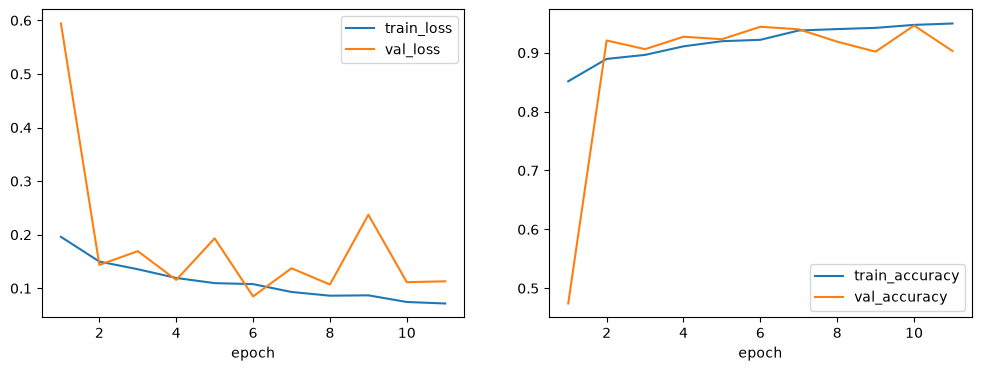

In [10]:
history_df=pd.DataFrame(history)
fig,axes=plt.subplots(1,2,figsize=(12,4))
history_df.plot(x='epoch',y=['train_loss','val_loss'],ax=axes[0]); history_df.plot(x='epoch',y=['train_accuracy','val_accuracy'],ax=axes[1]); plt.show()

## 16. Model Evaluation

In [11]:
test_loss,y_true,y_score=run_epoch(test_loader)
y_pred=(y_score>=checkpoint['threshold']).astype(int)
tn,fp,fn,tp=confusion_matrix(y_true,y_pred,labels=[0,1]).ravel()
metrics=dict(accuracy=accuracy_score(y_true,y_pred),precision=precision_score(y_true,y_pred,zero_division=0),recall=recall_score(y_true,y_pred,zero_division=0),specificity=float(tn/(tn+fp)),f1=f1_score(y_true,y_pred,zero_division=0),roc_auc=roc_auc_score(y_true,y_score))
display(pd.Series(metrics,name='Held-out test results'))

accuracy       0.833333
precision      0.796680
recall         0.984615
specificity    0.581197
f1             0.880734
roc_auc        0.929312
Name: Held-out test results, dtype: float64

## 17. Confusion Matrix
TP: pneumonia correctly flagged; TN: normal correctly classified; FP: normal flagged; FN: pneumonia missed. False negatives could delay further assessment; this prototype must not guide care.


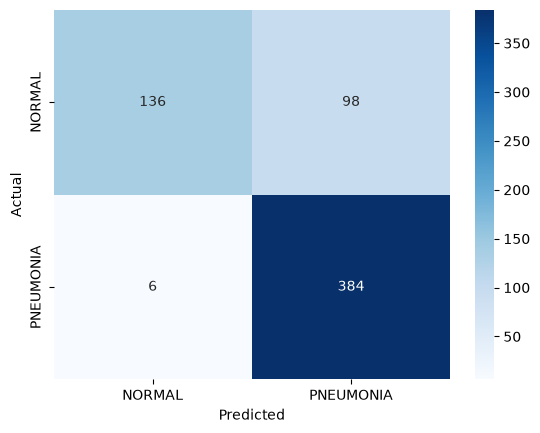

In [12]:
sns.heatmap(confusion_matrix(y_true,y_pred),annot=True,fmt='d',cmap='Blues',xticklabels=app.CLASS_MAP,yticklabels=app.CLASS_MAP)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

## 18. ROC Curve

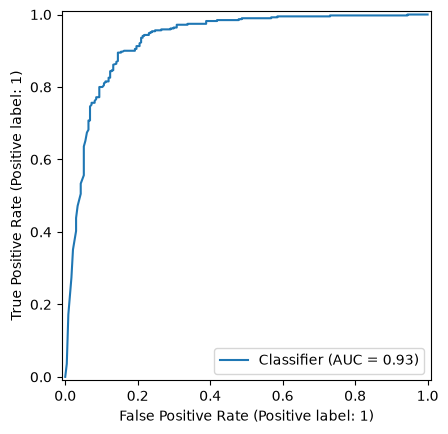

In [13]:
RocCurveDisplay.from_predictions(y_true,y_score); plt.show()

## 19. Precision, Recall, and F1 Analysis
Precision: fraction of positive predictions correct. Recall/sensitivity: fraction of pneumonia found. Specificity: fraction of normal correctly rejected. F1 balances precision and recall. Scores are not calibrated clinical probabilities.

In [14]:
print(classification_report(y_true,y_pred,target_names=list(app.CLASS_MAP),zero_division=0))

              precision    recall  f1-score   support

      NORMAL       0.96      0.58      0.72       234
   PNEUMONIA       0.80      0.98      0.88       390

    accuracy                           0.83       624
   macro avg       0.88      0.78      0.80       624
weighted avg       0.86      0.83      0.82       624



## 20. Sample Predictions

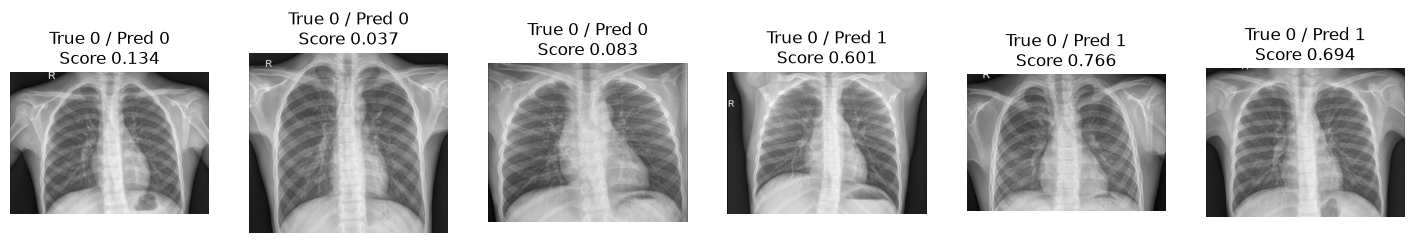

Correct examples: 3 misclassified: 3


In [15]:
correct=np.flatnonzero(y_true==y_pred)[:3]; wrong=np.flatnonzero(y_true!=y_pred)[:3]
indices=np.concatenate([correct,wrong]); fig,axes=plt.subplots(1,len(indices),figsize=(3*len(indices),3),squeeze=False)
for ax,i in zip(axes[0],indices):
    with Image.open(test_df.iloc[i].path) as im: ax.imshow(im,cmap='gray')
    ax.set_title(f'True {int(y_true[i])} / Pred {y_pred[i]}\nScore {y_score[i]:.3f}'); ax.axis('off')
plt.show(); print('Correct examples:',len(correct),'misclassified:',len(wrong))

## 21. Grad-CAM Visualization
Regions influencing the score are not proof of actual lesions. Hooks are always released.

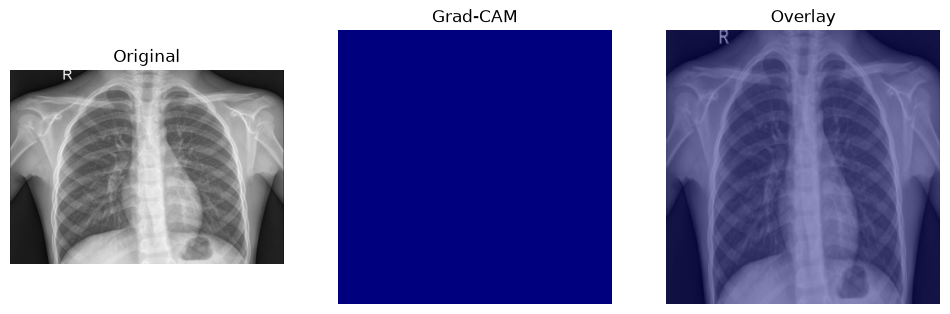

In [16]:
def gradcam(model,image):
    activations=[]; gradients=[]; layer=model.features[12]
    h1=layer.register_forward_hook(lambda m,i,o:activations.append(o))
    h2=layer.register_full_backward_hook(lambda m,gi,go:gradients.append(go[0]))
    try:
        model.eval(); model.zero_grad(set_to_none=True)
        model(eval_transform(image).unsqueeze(0).to(device)).sum().backward()
        cam=(gradients[0].mean((2,3),keepdim=True)*activations[0]).sum(1).relu()
        cam=torch.nn.functional.interpolate(cam.unsqueeze(1),size=(224,224),mode='bilinear',align_corners=False)[0,0].detach().cpu().numpy()
        return cam/(cam.max()+1e-8)
    finally: h1.remove(); h2.remove(); model.zero_grad(set_to_none=True)
with Image.open(test_df.iloc[0].path) as im: example=im.convert('RGB')
heat=gradcam(model,example); fig,axes=plt.subplots(1,3,figsize=(12,4))
axes[0].imshow(example); axes[1].imshow(heat,cmap='jet'); axes[2].imshow(example.resize((224,224))); axes[2].imshow(heat,cmap='jet',alpha=0.4)
for ax,title in zip(axes,['Original','Grad-CAM','Overlay']): ax.set_title(title); ax.axis('off')
plt.show()

## 22. Model Saving

In [17]:
checkpoint.update(history=history,training_seconds=training_seconds,test_metrics=metrics)
torch.save(checkpoint,checkpoint_path)
print('Saved best model:',checkpoint_path.name)

Saved best model: securemed_model.pth


## 23. Model Loading Verification

In [18]:
app_model,app_metadata=app.load_model(checkpoint_path)
raw_example=Path(test_df.iloc[0].path).read_bytes(); app_result=app.predict(raw_example,app_model,app_metadata)
model_cpu=SecureMedCNN().eval(); model_cpu.load_state_dict(checkpoint['state_dict'])
with torch.inference_mode(): notebook_score=model_cpu(eval_transform(app.validate_image(raw_example)).unsqueeze(0)).sigmoid().item()
assert abs(notebook_score-app_result['score'])<1e-7
assert abs(float(y_score[0])-notebook_score)<0.005
print('Notebook/application CPU prediction parity: PASS',app_result)

Notebook/application CPU prediction parity: PASS {'label': 'NORMAL', 'score': 0.1336650252342224, 'threshold': 0.5, 'model_version': 'custom-cnn-v1', 'inference_seconds': 0.07911789999343455}


## 24. Encryption Fundamentals
Encryption conceals plaintext. Hashing makes a fingerprint, but an attacker could replace both data and an unprotected hash. AES-GCM supplies authenticated encryption. Argon2id is an expensive salted login-password hash. Scrypt separately derives a vault key from the master passphrase.
## 25. AES-256-GCM Implementation
Shared functions: generate_key, encrypt_bytes, decrypt_bytes, verify_integrity. Each operation uses a fresh random 96-bit nonce and associated data binding record ID and field type. Nonce collisions are probabilistically negligible, not mathematically impossible. Never print keys.


In [2]:
demo_key=app.generate_key()
demo_cipher,demo_nonce=app.encrypt_bytes(demo_key,b'fictional demo','demo','details')
assert app.decrypt_bytes(demo_key,demo_cipher,demo_nonce,'demo','details')==b'fictional demo'
print('Authenticated encryption round trip: PASS')

Authenticated encryption round trip: PASS


## 26. Secure SQLite Database
Foreign keys, parameter binding and transactions protect consistency. Sensitive fields are ciphertext; IDs, timestamps, roles, relationships and model versions remain metadata. Audit logs exclude patient details and secrets.


In [3]:
persistent_store=app.Store(BASE/'securemed.db')
print('Legacy experiment schema initialized. The React website uses its own patient database.')

Schema initialized. Create first admin interactively in Streamlit; no default credentials.


## 27. Password Hashing and Authentication
Initial setup asks for an admin password and a separate master passphrase. Five failed logins trigger a 60-second lock. Session tokens expire after 30 minutes. Logout drops references; Python cannot guarantee key-memory zeroization.
## 28. Role-Based Authorization
Admins create users and read audit metadata. Only active doctors with administrator-assigned PATIENT_ACCESS can access patients. Viewers require patient READ access plus an explicit record grant. Administrators manage roles, active flags and permissions, but cannot decrypt medical records. Professional credential checks happen offline; registration proves no qualification. Checks occur in database methods. Local Python code and master-key holders remain trusted.
## 29. Encrypted Medical Image Storage
Image bytes and prediction JSON (including SHA-256) are encrypted separately. Authorization precedes authenticated decryption. Images are reconstructed in memory. The integrated experiment below uses actual trained-model inference.
## 30. Secure Transmission Demonstration
A temporary localhost certificate is explicitly trusted; hostname verification stays enabled. TLS 1.2 minimum. Loopback only, four-byte length framing, complete-read loops, timeouts and cleanup. AES protects application data independently of TLS. Local legacy notebook demonstration HTTP does not provide TLS; remote hosting needs HTTPS.


In [4]:
import ssl,socket,struct,threading,datetime,ipaddress
from cryptography import x509
from cryptography.x509.oid import NameOID
from cryptography.hazmat.primitives import hashes,serialization
from cryptography.hazmat.primitives.asymmetric import rsa

def tls_demo():
    start=time.perf_counter(); key=app.generate_key(); errors=[]; versions=[]; roundtrips=[]
    def recv_exact(sock,n):
        data=bytearray()
        while len(data)<n:
            part=sock.recv(n-len(data))
            if not part: raise ConnectionError('Truncated frame')
            data.extend(part)
        return bytes(data)
    def receive(sock):
        size=struct.unpack('!I',recv_exact(sock,4))[0]
        if size>1024*1024: raise ValueError('Frame too large')
        return recv_exact(sock,size)
    def send(sock,data): sock.sendall(struct.pack('!I',len(data))+data)
    with tempfile.TemporaryDirectory(prefix='securemed_tls_') as temp:
        private=rsa.generate_private_key(public_exponent=65537,key_size=2048)
        name=x509.Name([x509.NameAttribute(NameOID.COMMON_NAME,'localhost')]); utc=datetime.datetime.now(datetime.timezone.utc)
        cert=(x509.CertificateBuilder().subject_name(name).issuer_name(name).public_key(private.public_key()).serial_number(x509.random_serial_number()).not_valid_before(utc-datetime.timedelta(minutes=1)).not_valid_after(utc+datetime.timedelta(hours=1)).add_extension(x509.SubjectAlternativeName([x509.DNSName('localhost'),x509.IPAddress(ipaddress.ip_address('127.0.0.1'))]),critical=False).sign(private,hashes.SHA256()))
        cp,kp=Path(temp)/'cert.pem',Path(temp)/'key.pem'
        cp.write_bytes(cert.public_bytes(serialization.Encoding.PEM))
        kp.write_bytes(private.private_bytes(serialization.Encoding.PEM,serialization.PrivateFormat.PKCS8,serialization.NoEncryption()))
        sc=ssl.SSLContext(ssl.PROTOCOL_TLS_SERVER); sc.minimum_version=ssl.TLSVersion.TLSv1_2; sc.load_cert_chain(cp,kp)
        cc=ssl.create_default_context(cafile=str(cp)); cc.minimum_version=ssl.TLSVersion.TLSv1_2
        with socket.socket() as listener:
            listener.bind(('127.0.0.1',0)); listener.listen(1); listener.settimeout(10)
            def server():
                try:
                    conn,_=listener.accept()
                    with conn:
                        conn.settimeout(10)
                        with sc.wrap_socket(conn,server_side=True) as secured:
                            msg=json.loads(receive(secured))
                            plain=app.decrypt_bytes(key,bytes.fromhex(msg['cipher']),bytes.fromhex(msg['nonce']),'tls-demo','payload')
                            assert json.loads(plain)=={'fictional_id':'DEMO-ONLY','purpose':'education'}
                            send(secured,b'ACK: authenticated fictional record')
                except Exception as e: errors.append(e)
            thread=threading.Thread(target=server,daemon=True); thread.start()
            try:
                with socket.create_connection(listener.getsockname(),timeout=10) as sock:
                    with cc.wrap_socket(sock,server_hostname='localhost') as secured:
                        versions.append(secured.version())
                        cipher,nonce=app.encrypt_bytes(key,json.dumps({'fictional_id':'DEMO-ONLY','purpose':'education'}).encode(),'tls-demo','payload')
                        rt=time.perf_counter(); send(secured,json.dumps({'cipher':cipher.hex(),'nonce':nonce.hex()}).encode())
                        assert receive(secured)==b'ACK: authenticated fictional record'
                        roundtrips.append(time.perf_counter()-rt)
            finally: thread.join(timeout=12)
            if thread.is_alive(): raise TimeoutError('Server did not terminate')
            if errors: raise errors[0]
    return dict(status='PASS',tls=versions[0],round_trip_seconds=roundtrips[0],setup_and_round_trip_seconds=time.perf_counter()-start)
tls_result=tls_demo(); print(tls_result)

{'status': 'PASS', 'tls': 'TLSv1.3', 'round_trip_seconds': 0.0020066999131813645, 'setup_and_round_trip_seconds': 0.19867009995505214}


## 31. Security Testing
Isolated temporary databases and random disposable credentials. Actual PASS/FAIL results; failures stop the notebook. No security experiment damages application records.

In [5]:
from cryptography.exceptions import InvalidTag
from argon2.exceptions import VerifyMismatchError
import sqlite3
security_results=[]
def check(name,fn):
    try:
        value=fn()
        if value is False: raise AssertionError('Returned false')
        security_results.append(dict(test=name,status='PASS',detail=''))
    except Exception as e: security_results.append(dict(test=name,status='FAIL',detail=type(e).__name__+': '+str(e)))
def rejected(fn,expected):
    try: fn()
    except expected: return True
    raise AssertionError('Operation unexpectedly succeeded')
with tempfile.TemporaryDirectory(prefix='securemed_tests_') as temp:
    db=Path(temp)/'test.db'; store=app.Store(db)
    password=secrets.token_urlsafe(24); master=secrets.token_urlsafe(32)
    store.bootstrap('admin_demo',password,master); admin=store.login('admin_demo',password)
    store.create_user(admin,'doctor_demo',password,'DOCTOR')
    viewer_id=store.create_user(admin,'viewer_demo',password,'VIEWER')
    store.create_user(admin,'other_doctor',password,'DOCTOR')
    doctor=store.login('doctor_demo',password); viewer=store.login('viewer_demo',password); other=store.login('other_doctor',password)
    key=store.unlock(doctor,master)
    pid=store.register_patient(doctor,key,dict(fictional_name='Fictional Example',age=30))
    store.assign_patient(admin,pid,'doctor_demo','WRITE')
    buf=io.BytesIO(); Image.new('RGB',(32,32),'gray').save(buf,format='PNG'); image_bytes=buf.getvalue()
    rid=store.save_record(doctor,key,pid,image_bytes,dict(label='DEMO_ONLY',score=0.,model_version='security-test-not-model'),store.patient_version(doctor,pid))
    cipher,nonce=app.encrypt_bytes(key,b'example',rid,'test')
    check('AES round trip',lambda:app.decrypt_bytes(key,cipher,nonce,rid,'test')==b'example')
    check('Wrong key',lambda:rejected(lambda:app.decrypt_bytes(app.generate_key(),cipher,nonce,rid,'test'),InvalidTag))
    check('Ciphertext tampering',lambda:rejected(lambda:app.decrypt_bytes(key,bytes([cipher[0]^1])+cipher[1:],nonce,rid,'test'),InvalidTag))
    check('Tag tampering',lambda:rejected(lambda:app.decrypt_bytes(key,cipher[:-1]+bytes([cipher[-1]^1]),nonce,rid,'test'),InvalidTag))
    check('Record ID tampering',lambda:rejected(lambda:app.decrypt_bytes(key,cipher,nonce,'other','test'),InvalidTag))
    check('Field substitution',lambda:rejected(lambda:app.decrypt_bytes(key,cipher,nonce,rid,'other'),InvalidTag))
    check('Image recovery',lambda:store.retrieve(doctor,key,rid)[1]==image_bytes)
    check('SHA-256',lambda:app.verify_integrity(image_bytes,hashlib.sha256(image_bytes).hexdigest()))
    hashed=app.PH.hash(password)
    check('Salted Argon2id',lambda:hashed.startswith('$argon2id$') and app.PH.hash(password)!=hashed)
    check('Correct password',lambda:app.PH.verify(hashed,password))
    check('Wrong password',lambda:rejected(lambda:app.PH.verify(hashed,'incorrect'),VerifyMismatchError))
    check('SQL injection',lambda:rejected(lambda:store.login("' OR 1=1 --",password),PermissionError))
    check('Unauthorized viewer',lambda:rejected(lambda:store.retrieve(viewer,key,rid),PermissionError))
    check('Other doctor',lambda:rejected(lambda:store.retrieve(other,key,rid),PermissionError))
    check('Role restriction',lambda:rejected(lambda:store.create_user(doctor,'bad_user',password,'ADMIN'),PermissionError))
    check('Admin cannot read clinical data',lambda:rejected(lambda:store.retrieve(admin,key,rid),PermissionError))
    reopened=app.Store(db); again=reopened.login('doctor_demo',password)
    check('SQLite persistence',lambda:reopened.retrieve(again,key,rid)[1]==image_bytes)
    def foreign_key():
        with store.db() as c: c.execute('INSERT INTO grants VALUES(?,?)',('missing',viewer_id))
    check('Foreign keys',lambda:rejected(foreign_key,sqlite3.IntegrityError))
    check('1000 random nonces unique',lambda:len({app.encrypt_bytes(key,b'x','nonce','test')[1] for _ in range(1000)})==1000)
    check('Verified TLS',lambda:tls_result['status']=='PASS')
    check('Invalid image',lambda:rejected(lambda:app.validate_image(b'not image'),ValueError))
    check('Oversized upload',lambda:rejected(lambda:app.validate_image(b'x'*(app.MAX_UPLOAD+1)),ValueError))
    check('Missing model',lambda:rejected(lambda:app.load_model(Path(temp)/'absent.pth'),FileNotFoundError))
    store.grant(admin,rid,'viewer_demo')
    check('Explicit viewer grant',lambda:store.retrieve(viewer,key,rid)[1]==image_bytes)
    store.logout(viewer)
    check('Logout invalidation',lambda:rejected(lambda:store.records(viewer),PermissionError))
    check('Wrong master',lambda:rejected(lambda:store.unlock(doctor,secrets.token_urlsafe(32)),InvalidTag))
    check('No plaintext patient in database',lambda:b'Fictional Example' not in db.read_bytes())
    for _ in range(5):
        try: store.login('other_doctor','wrong')
        except PermissionError: pass
    check('Login lockout',lambda:rejected(lambda:store.login('other_doctor',password),PermissionError))
display(pd.DataFrame(security_results))
assert all(r['status']=='PASS' for r in security_results),'Investigate security test failures.'

,test,status,detail
0,AES round trip,PASS,
1,Wrong key,PASS,
2,Ciphertext tampering,PASS,
3,Tag tampering,PASS,
4,Record ID tampering,PASS,
5,Field substitution,PASS,
6,Image recovery,PASS,
7,SHA-256,PASS,
8,Salted Argon2id,PASS,
9,Correct password,PASS,


In [6]:
import sys,tempfile,secrets,io,sqlite3
from pathlib import Path
sys.dont_write_bytecode=True; sys.path.insert(0,str(Path('SecureMed_AI').resolve()))
import research_support as app
from PIL import Image
results=[]
def check(name,fn):
 try:
  assert fn() is not False
  results.append((name,'PASS'))
 except Exception as e:
  results.append((name,'FAIL '+type(e).__name__+': '+str(e)))
def rejected(fn,kind=PermissionError):
 try: fn()
 except kind: return True
 raise AssertionError('Unexpected authorization')
with tempfile.TemporaryDirectory(prefix='securemed_access_') as temp:
 store=app.Store(Path(temp)/'db.sqlite'); password=secrets.token_urlsafe(24); master=secrets.token_urlsafe(32)
 store.bootstrap('admin_test',password,master); admin=store.login('admin_test',password)
 aid=store.create_user(admin,'doctor_a',password,'DOCTOR'); bid=store.create_user(admin,'doctor_b',password,'DOCTOR')
 store.create_user(admin,'viewer_test',password,'VIEWER')
 a=store.login('doctor_a',password); b=store.login('doctor_b',password); viewer=store.login('viewer_test',password)
 key=store.unlock(a,master)
 pa=store.register_patient(a,key,dict(fictional_name='Fictional A',age=25))
 pb=store.register_patient(b,key,dict(fictional_name='Fictional B',age=35))
 check('Creator cannot self-assign',lambda:rejected(lambda:store.view_patient(a,key,pa)))
 check('Doctor cannot grant patient permissions',lambda:rejected(lambda:store.assign_patient(a,pa,'doctor_a','WRITE')))
 store.assign_patient(admin,pa,'doctor_a','WRITE'); store.assign_patient(admin,pb,'doctor_b','WRITE')
 buf=io.BytesIO(); Image.new('RGB',(32,32)).save(buf,format='PNG'); raw=buf.getvalue(); pred=dict(label='TEST',score=0.,model_version='test-only')
 check('Doctor A cannot view B',lambda:rejected(lambda:store.view_patient(a,key,pb)))
 check('Doctor A cannot edit B',lambda:rejected(lambda:store.edit_patient(a,key,pb,dict(fictional_name='Altered',age=30),1)))
 check('Doctor A cannot save prediction to B',lambda:rejected(lambda:store.save_record(a,key,pb,raw,pred,1)))
 check('Doctor A cannot upload or predict for B',lambda:rejected(lambda:store.predict_for_patient(a,pb,raw,None,{})))
 check('Admin cannot decrypt',lambda:rejected(lambda:store.view_patient(admin,key,pa)))
 check('Admin cannot unlock vault',lambda:rejected(lambda:store.unlock(admin,master)))
 check('Forged session token denied',lambda:rejected(lambda:store.view_patient(aid,key,pa)))
 version=store.patient_version(a,pa)
 check('Authorized edit',lambda:store.edit_patient(a,key,pa,dict(fictional_name='Fictional A updated',age=26),version)==version+1)
 check('Stale concurrent edit rejected',lambda:rejected(lambda:store.edit_patient(a,key,pa,dict(fictional_name='Stale',age=20),version),ValueError))
 check('Encrypted edit history retained',lambda:len(store.patient_history(a,key,pa))==2)
 r1=store.save_record(a,key,pa,raw,pred,store.patient_version(a,pa))
 check('Stale prediction save rejected',lambda:rejected(lambda:store.save_record(a,key,pa,raw,pred,version),ValueError))
 r2=store.save_record(a,key,pa,raw,pred,store.patient_version(a,pa))
 check('Prediction history append only',lambda:r1!=r2 and len(store.records(a))==2 and store.retrieve(a,key,r1)[1]==raw)
 store.assign_patient(admin,pa,'viewer_test','READ')
 check('Patient permission alone insufficient for viewer',lambda:rejected(lambda:store.retrieve(viewer,key,r1)))
 store.grant(admin,r1,'viewer_test')
 check('Explicit viewer record allowed',lambda:store.retrieve(viewer,key,r1)[1]==raw)
 check('Other record hidden from viewer',lambda:rejected(lambda:store.retrieve(viewer,key,r2)))
 check('Viewer cannot edit',lambda:rejected(lambda:store.edit_patient(viewer,key,pa,dict(fictional_name='Bad',age=1),4)))
 check('Doctor cannot promote account',lambda:rejected(lambda:store.manage_user(a,'doctor_b','ADMIN',True)))
 store.assign_patient(admin,pa,'doctor_a','READ')
 check('Read-only doctor cannot modify',lambda:rejected(lambda:store.edit_patient(a,key,pa,dict(fictional_name='Bad',age=1),4)))
 store.manage_user(admin,'doctor_a','DOCTOR',False)
 check('Inactive existing session rejected',lambda:rejected(lambda:store.view_patient(a,key,pa)))
 check('Inactive login rejected',lambda:rejected(lambda:store.login('doctor_a',password)))
 store.manage_user(admin,'doctor_a','DOCTOR',True)
 check('Reactivation does not restore grants',lambda:rejected(lambda:store.view_patient(a,key,pa)))
 store.manage_user(admin,'doctor_b','VIEWER',True)
 check('Doctor role revocation immediate',lambda:rejected(lambda:store.edit_patient(b,key,pb,dict(fictional_name='Bad',age=1),1)))
 store.grant(admin,r1,'viewer_test',True)
 check('Record permission revocation immediate',lambda:rejected(lambda:store.retrieve(viewer,key,r1)))
 logs=store.audit_rows(admin)
 check('Successful modification audit',lambda:any(r['action']=='EDIT_PATIENT' and r['status']=='OK' for r in logs))
 check('Denied modification audit',lambda:any(r['action']=='EDIT_PATIENT' and r['status']=='DENIED' and r['actor_id']==aid for r in logs))
 check('Version conflict audit',lambda:any(r['action']=='EDIT_PATIENT' and r['status']=='REJECTED' for r in logs))
 check('No plaintext patient names on disk',lambda:b'Fictional A' not in Path(store.path).read_bytes())
for name,result in results: print(result,name)
assert all(result=='PASS' for _,result in results)
print('PATIENT AUTHORIZATION TESTS:',len(results),'PASS')


PASS Creator cannot self-assign
PASS Doctor cannot grant patient permissions
PASS Doctor A cannot view B
PASS Doctor A cannot edit B
PASS Doctor A cannot save prediction to B
PASS Doctor A cannot upload or predict for B
PASS Admin cannot decrypt
PASS Admin cannot unlock vault
PASS Forged session token denied
PASS Authorized edit
PASS Stale concurrent edit rejected
PASS Encrypted edit history retained
PASS Stale prediction save rejected
PASS Prediction history append only
PASS Patient permission alone insufficient for viewer
PASS Explicit viewer record allowed
PASS Other record hidden from viewer
PASS Viewer cannot edit
PASS Doctor cannot promote account
PASS Read-only doctor cannot modify
PASS Inactive existing session rejected
PASS Inactive login rejected
PASS Reactivation does not restore grants
PASS Doctor role revocation immediate
PASS Record permission revocation immediate
PASS Successful modification audit
PASS Denied modification audit
PASS Version conflict audit
PASS No plainte

## 32. Integrated End-to-End Demonstration

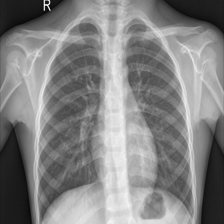

Actual inference: NORMAL score: 0.1336650252342224
Doctor authentication â†’ patient â†’ inference â†’ encrypted storage â†’ authorized recovery: PASS
Unauthorized retrieval and tampered ciphertext rejected


,log_id,actor_id,action,record_reference,timestamp,status
0,14,d97b570d84504b2ca633965115e93931,READ_RECORD,NaN,2026-11-01T14:57:42.661114+00:00,DENIED
1,13,6adf3bb6a91c4cc291316ed8299d310d,READ_RECORD,9334772a6a83456d9ac5df2e6c40e669,2026-11-01T14:57:42.654351+00:00,OK
2,12,6adf3bb6a91c4cc291316ed8299d310d,SAVE_RECORD,c7d0ea850ac1414b873dc09b4b3ec4d4,2026-11-01T14:57:42.647150+00:00,OK
3,11,6adf3bb6a91c4cc291316ed8299d310d,PREDICTION_APPENDED,9334772a6a83456d9ac5df2e6c40e669,2026-11-01T14:57:42.647103+00:00,OK
4,10,6adf3bb6a91c4cc291316ed8299d310d,UPLOAD_AND_PREDICT,c7d0ea850ac1414b873dc09b4b3ec4d4,2026-11-01T14:57:42.628334+00:00,OK
5,9,161f887c5ec74ec7a599cdd942f89b8e,ASSIGN_PATIENT,c7d0ea850ac1414b873dc09b4b3ec4d4,2026-11-01T14:57:42.582130+00:00,OK
6,8,6adf3bb6a91c4cc291316ed8299d310d,REGISTER_PATIENT,NaN,2026-11-01T14:57:42.574066+00:00,OK
7,7,6adf3bb6a91c4cc291316ed8299d310d,PATIENT_AWAITING_ASSIGNMENT,c7d0ea850ac1414b873dc09b4b3ec4d4,2026-11-01T14:57:42.573996+00:00,OK
8,6,d97b570d84504b2ca633965115e93931,LOGIN,NaN,2026-11-01T14:57:42.471186+00:00,OK
9,5,6adf3bb6a91c4cc291316ed8299d310d,LOGIN,NaN,2026-11-01T14:57:42.336829+00:00,OK


In [7]:
with tempfile.TemporaryDirectory(prefix='securemed_e2e_') as temp:
    store=app.Store(Path(temp)/'demo.db'); password=secrets.token_urlsafe(24); master=secrets.token_urlsafe(32)
    store.bootstrap('demo_admin',password,master); admin=store.login('demo_admin',password)
    store.create_user(admin,'demo_doctor',password,'DOCTOR'); store.create_user(admin,'demo_viewer',password,'VIEWER')
    doctor=store.login('demo_doctor',password); viewer=store.login('demo_viewer',password); key=store.unlock(doctor,master)
    pid=store.register_patient(doctor,key,dict(fictional_name='Fictional Patient Alpha',age=28))
    store.assign_patient(admin,pid,'demo_doctor','WRITE')
    prediction,version=store.predict_for_patient(doctor,pid,raw_example,app_model,app_metadata)
    start=time.perf_counter(); rid=store.save_record(doctor,key,pid,raw_example,prediction,version); insertion_seconds=time.perf_counter()-start
    start=time.perf_counter(); details,recovered,result=store.retrieve(doctor,key,rid); retrieval_seconds=time.perf_counter()-start
    assert recovered==raw_example
    assert rejected(lambda:store.retrieve(viewer,key,rid),PermissionError)
    cipher,nonce=app.encrypt_bytes(key,raw_example,'isolated','image')
    assert rejected(lambda:app.decrypt_bytes(key,cipher[:-1]+bytes([cipher[-1]^1]),nonce,'isolated','image'),InvalidTag)
    display(app.validate_image(recovered).resize((224,224)))
    print('Actual inference:',result['label'],'score:',result['score'])
    print('Doctor authentication â†’ patient â†’ inference â†’ encrypted storage â†’ authorized recovery: PASS')
    print('Unauthorized retrieval and tampered ciphertext rejected')
    display(pd.DataFrame(store.audit_rows(admin)))

## 33. Performance Analysis

In [8]:
timings=[]
for _ in range(20):
    start=time.perf_counter(); cipher,nonce=app.encrypt_bytes(demo_key,raw_example,'benchmark','image'); encrypted=time.perf_counter()-start
    start=time.perf_counter(); app.decrypt_bytes(demo_key,cipher,nonce,'benchmark','image'); timings.append((encrypted,time.perf_counter()-start))
display(pd.Series(dict(metrics,training_seconds=training_seconds,inference_seconds=app_result['inference_seconds'],encryption_seconds=float(np.mean(timings,axis=0)[0]),decryption_seconds=float(np.mean(timings,axis=0)[1]),database_insert_seconds=insertion_seconds,database_retrieval_seconds=retrieval_seconds,ciphertext_and_nonce_overhead_bytes=len(cipher)+len(nonce)-len(raw_example),tls_round_trip_seconds=tls_result['round_trip_seconds'])))
print('Hardware, image size, caching and background load affect timings. Database timings include crypto and audit writes.')

accuracy                                 0.833333
precision                                0.796680
recall                                   0.984615
specificity                              0.581197
f1                                       0.880734
roc_auc                                  0.929312
training_seconds                       421.511157
inference_seconds                        0.094282
encryption_seconds                       0.000076
decryption_seconds                       0.000067
database_insert_seconds                  0.018751
database_retrieval_seconds               0.006987
ciphertext_and_nonce_overhead_bytes     28.000000
tls_round_trip_seconds                   0.002007
dtype: float64

Hardware, image size, caching and background load affect timings. Database timings include crypto and audit writes.


## 34. Limitations
Educational prototype, not approved for diagnosis. Dataset demographics/institutions limit generalization. Filename groups do not independently validate patient identity. Grad-CAM does not prove clinical correctness. A frozen-backbone ResNet18 comparison is included in the final section. Test duplicates are reported above.

Notebook/local operators and shared master-key holders are trusted. legacy notebook demonstration state is not production authentication. SQLite metadata is visible. AES-GCM protects encrypted fields, not the operating system, memory or availability. Audit records are not tamper-proof against filesystem administrators. Key loss can make data unrecoverable; rotation, secure backup and per-user key wrapping need more engineering. Random nonce uniqueness is probabilistic. Remote use requires correctly configured TLS and extensive security review. No HIPAA/regulatory compliance is claimed. Never use real patient information.
## 35. Conclusion
Executed outputs provide evidence of measured CNN results, compatible inference, authenticated encryption, authorization and verified TLS. An accuracy score does not establish clinical value. Confidentiality comes from encryption/access controls; integrity from AEAD; availability still requires backups and operational controls.

### Demonstration instructions
Use the project .venv, run all notebook cells, then `cd SecureMed_AI` and `Use the React website at http://127.0.0.1:8000`. Create admin and master passphrase interactively; create doctor/viewer accounts. As doctor, unlock vault, register fictional patient, classify public X-ray, store, retrieve, verify, and ask the administrator to grant viewer access. Full isolated security and TLS results are above.

### College viva readiness
- **CNN:** learns local image filters and combines features for classification.
- **PyTorch:** tensors and automatic differentiation for neural-network training.
- **CUDA:** NVIDIA GPU computing platform.
- **Pneumonia classification:** predicting dataset labels, not diagnosing patients.
- **Preprocessing:** consistent conversion, resizing and normalization.
- **Overfitting:** memorizing training patterns that do not generalize.
- **Confusion matrix:** actual versus predicted class counts.
- **Precision / recall:** correct positive predictions / positives found.
- **AES-256-GCM:** authenticated symmetric encryption with a 256-bit key.
- **Nonce:** per-encryption value that must not repeat for a key.
- **Authentication tag:** keyed check that detects modified ciphertext/associated data.
- **Argon2id:** memory-hard password hashing to slow guessing.
- **SHA-256:** cryptographic fingerprint; not encryption or sufficient password protection.
- **SQL injection:** input interpreted as SQL; bound parameters separate code and values.
- **RBAC:** roles limit actions; ownership/grants further restrict records.
- **TLS:** certificate-verified encrypted transport.
- **CIA:** confidentiality, integrity, availability.
- **Confidentiality here:** encrypted fields and authenticated, authorized access.
- **Tamper detection:** AES-GCM binds encrypted data to record and field identity.
- **Limitations:** educational data/model, trusted local operator, visible metadata, no clinical/compliance validation.


## Storage and authorization extensions
Dataset and model stay outside SQLite. Only explicit authorized saves write image BLOBs; the original bytes are retained without lossy recompression. SHA-256 fingerprints are encrypted with predictions. Patient-scoped HMAC lookup tokens allow duplicate image reuse without publishing raw fingerprints. Each new prediction keeps its own immutable record and authenticated image reference. No decrypted images are written to persistent disk. Set SECUREMED_MAX_UPLOAD_MB (1?100, default 10) before launching; both upload widget and server validation enforce it. Admin dashboard reports database and encrypted image bytes.

For future growth, migrate BLOBs to separately encrypted files using opaque IDs, restrictive filesystem permissions, verified AEAD tags, an atomic database-reference transition, backups and a recovery plan. Never migrate plaintext or weaken record authorization. This migration is a design option, not implemented storage.

Patient edits use expected-version checks, transactions and encrypted history. Prediction saves increment the same patient version and append records. Admin revocation is checked against current database state on each operation. A new patient awaits admin assignment even when created by a doctor.


In [1]:
import sys,tempfile,secrets,io
from pathlib import Path
sys.dont_write_bytecode=True; sys.path.insert(0,str(Path.cwd()))
import research_support as app
from PIL import Image
with tempfile.TemporaryDirectory() as temp:
 s=app.Store(Path(temp)/'test.db'); pw=secrets.token_urlsafe(24); master=secrets.token_urlsafe(32)
 s.bootstrap('admin',pw,master); a=s.login('admin',pw); s.create_user(a,'doctor',pw,'DOCTOR'); d=s.login('doctor',pw); k=s.unlock(d,master)
 p=s.register_patient(d,k,dict(fictional_name='Fictional storage',age=22)); s.assign_patient(a,p,'doctor','WRITE')
 b=io.BytesIO(); Image.new('RGB',(40,40),'white').save(b,format='PNG'); raw=b.getvalue(); pred=dict(label='TEST',model_version='test',score=0.)
 r1=s.save_record(d,k,p,raw,pred,1); r2=s.save_record(d,k,p,raw,pred,2)
 with s.db() as c:
  assert c.execute('SELECT COUNT(*) FROM encrypted_images').fetchone()[0]==1
  assert c.execute('SELECT COUNT(*) FROM medical_records').fetchone()[0]==2
  assert c.execute('SELECT SUM(length(encrypted_image)) FROM medical_records').fetchone()[0]==0
 assert s.retrieve(d,k,r1)[1]==raw and s.retrieve(d,k,r2)[1]==raw
 assert s.storage_stats(a)['encrypted_image_bytes']==len(raw)+28
 try: s.storage_stats(d); raise AssertionError('Doctor storage stats allowed')
 except PermissionError: pass
 with s.db() as c: c.execute('UPDATE encrypted_images SET ciphertext=?',(b'bad',))
 try: s.retrieve(d,k,r2); raise AssertionError('Tamper allowed')
 except app.InvalidTag: pass
 print('PASS: duplicate BLOB reuse; two prediction records; exact-byte recovery; storage accounting; admin restriction; shared BLOB tamper detection')


PASS: duplicate BLOB reuse; two prediction records; exact-byte recovery; storage accounting; admin restriction; shared BLOB tamper detection


Verification note: training and evaluation outputs were retained from the completed CUDA run. Security, authorization, storage and integrated demonstration cells were rerun in a fresh kernel after the application updates. Run-all executes the complete current implementation; execution counters reflect these verification sessions.

## ResNet18 comparison and application model selection
ImageNet-pretrained ResNet18 is an additional baseline. To minimize training time, the backbone is frozen and its features cached in RAM; only the final linear classifier is trained. It uses ImageNet normalization and the same patient-grouped training/validation split and original test set as the custom CNN. No test-based threshold tuning. The additional checkpoint is a runtime artifact, not an additional source file.

In [5]:
# ResNet18 transfer-learning baseline: freeze pretrained backbone for fast training.
from torchvision.models import resnet18, ResNet18_Weights
os.environ['TORCH_HOME']=str(Path(tempfile.gettempdir())/'securemed_torch')
torch.manual_seed(SEED)
resnet=resnet18(weights=ResNet18_Weights.DEFAULT).to(device)
for parameter in resnet.parameters(): parameter.requires_grad=False
resnet.fc=nn.Identity()
resnet.eval()
res_transform=app.preprocessing(app.RESNET_MEAN,app.RESNET_STD)
res_start=time.perf_counter()
def extract_resnet(df):
    loader=DataLoader(XrayDataset(df,res_transform),batch_size=32,num_workers=0,pin_memory=device.type=='cuda')
    features=[]; labels=[]
    with torch.inference_mode():
        for x,y in loader:
            features.append(resnet(x.to(device)).cpu()); labels.append(y)
    return torch.cat(features),torch.cat(labels)
train_features,train_targets=extract_resnet(train_df)
val_features,val_targets=extract_resnet(val_df)
print('Frozen training/validation features extracted',flush=True)
head=nn.Linear(512,1).to(device)
opt=torch.optim.AdamW(head.parameters(),lr=0.001,weight_decay=0.0001)
loss_fn=nn.BCEWithLogitsLoss(pos_weight=torch.tensor([(train_targets==0).sum()/(train_targets==1).sum()],device=device))
feature_loader=DataLoader(torch.utils.data.TensorDataset(train_features,train_targets),batch_size=128,shuffle=True,generator=torch.Generator().manual_seed(SEED))
best=float('inf'); patience=0; res_history=[]
for epoch in range(1,51):
    head.train(); total=0.
    for x,y in feature_loader:
        opt.zero_grad(); loss=loss_fn(head(x.to(device)).squeeze(1),y.to(device)); loss.backward(); opt.step(); total+=loss.item()*len(y)
    head.eval()
    with torch.inference_mode():
        logits=head(val_features.to(device)).squeeze(1)
        vl=loss_fn(logits,val_targets.to(device)).item()
        score=logits.sigmoid().cpu().numpy()
    res_history.append(dict(epoch=epoch,train_loss=total/len(train_targets),val_loss=vl,val_accuracy=accuracy_score(val_targets.numpy(),score>=0.5)))
    if vl<best-1e-4:
        best=vl; patience=0; best_head={k:v.detach().cpu().clone() for k,v in head.state_dict().items()}; best_epoch=epoch
    else: patience+=1
    if epoch%5==0: print(res_history[-1],flush=True)
    if patience>=7: break
head.load_state_dict(best_head)
resnet.fc=head; resnet.eval()
res_training_seconds=time.perf_counter()-res_start
# Evaluate original test split only after head selection.
res_test_loader=DataLoader(XrayDataset(test_df,res_transform),batch_size=32,num_workers=0)
res_y=[]; res_scores=[]
with torch.inference_mode():
    for x,y in res_test_loader:
        res_scores.extend(resnet(x.to(device)).squeeze(1).sigmoid().cpu().tolist()); res_y.extend(y.tolist())
res_y=np.array(res_y); res_scores=np.array(res_scores); res_pred=res_scores>=0.5
rtn,rfp,rfn,rtp=confusion_matrix(res_y,res_pred).ravel()
res_metrics=dict(accuracy=accuracy_score(res_y,res_pred),precision=precision_score(res_y,res_pred),recall=recall_score(res_y,res_pred),specificity=float(rtn/(rtn+rfp)),f1=f1_score(res_y,res_pred),roc_auc=roc_auc_score(res_y,res_scores))
res_ck=dict(state_dict={k:v.detach().cpu().clone() for k,v in resnet.state_dict().items()},architecture='ResNet18-v1',class_mapping=app.CLASS_MAP,image_size=224,mean=app.RESNET_MEAN,std=app.RESNET_STD,threshold=0.5,model_version='resnet18-imagenet-frozen-v1',trained=True,best_epoch=best_epoch,history=res_history,training_seconds=res_training_seconds,test_metrics=res_metrics,dataset_manifest_sha256=manifest_digest,training_config=dict(backbone='ImageNet ResNet18 frozen',classifier='Linear 512 to 1',max_epochs=50,patience=7,lr=0.001,seed=SEED,augmentation='none; deterministic cached frozen features'))
torch.save(res_ck,BASE/'securemed_resnet18.pth')


Frozen training/validation features extracted


{'epoch': 5, 'train_loss': 0.08830334554404257, 'val_loss': 0.0903761014342308, 'val_accuracy': 0.938753959873284}


{'epoch': 10, 'train_loss': 0.06771789842277844, 'val_loss': 0.07376640290021896, 'val_accuracy': 0.9461457233368532}


{'epoch': 15, 'train_loss': 0.05850311766592368, 'val_loss': 0.06800307333469391, 'val_accuracy': 0.9588173178458289}


{'epoch': 20, 'train_loss': 0.053402298436276516, 'val_loss': 0.06271535158157349, 'val_accuracy': 0.9609292502639916}


{'epoch': 25, 'train_loss': 0.04923581029227038, 'val_loss': 0.06040756404399872, 'val_accuracy': 0.9588173178458289}


{'epoch': 30, 'train_loss': 0.046886403699427606, 'val_loss': 0.05976635590195656, 'val_accuracy': 0.9619852164730729}


{'epoch': 35, 'train_loss': 0.044758907223911584, 'val_loss': 0.058204878121614456, 'val_accuracy': 0.9619852164730729}


{'epoch': 40, 'train_loss': 0.04224060919322565, 'val_loss': 0.05505000799894333, 'val_accuracy': 0.9619852164730729}


{'epoch': 45, 'train_loss': 0.03947591755470374, 'val_loss': 0.05444921553134918, 'val_accuracy': 0.9640971488912354}


{'epoch': 50, 'train_loss': 0.03913678540246153, 'val_loss': 0.05446302518248558, 'val_accuracy': 0.9619852164730729}


### Saved ResNet verification
The initial CPU/CUDA check used a 0.0001 score tolerance and detected a 0.000278 numerical difference. CPU-to-CPU architecture/preprocessing parity is checked separately at 1e-7. The cross-device check allows 0.005 and verifies the same label. Results below are from the saved checkpoint; no test-driven model tuning was performed.

CPU/application parity: 0.0 CPU/device score difference: 0.00027813762426376343


,accuracy,precision,recall,specificity,f1,roc_auc
Custom CNN,0.833333,0.796680,0.984615,0.581197,0.880734,0.929312
ResNet18 frozen backbone,0.854167,0.820128,0.982051,0.641026,0.893816,0.958931


ResNet training seconds: 273.44432789995335 selected epoch: 49


              precision    recall  f1-score   support

      NORMAL       0.96      0.64      0.77       234
   PNEUMONIA       0.82      0.98      0.89       390

    accuracy                           0.85       624
   macro avg       0.89      0.81      0.83       624
weighted avg       0.87      0.85      0.85       624



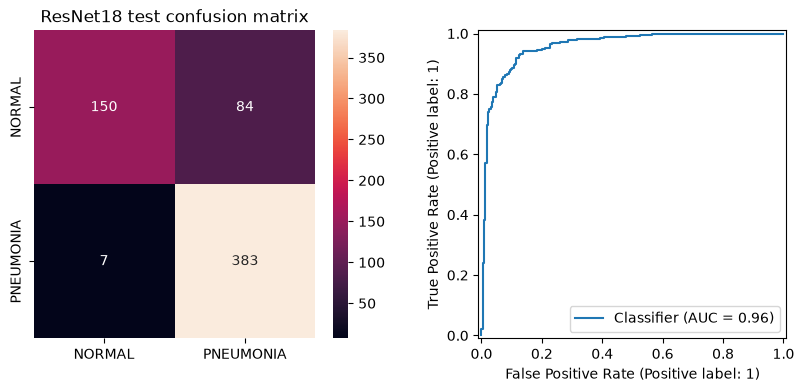

Saved ResNet checkpoint evaluation and application parity: PASS


In [5]:
# Reload the trained checkpoint; no retraining is needed for verification.
from torchvision.models import resnet18
loaded_res,res_meta=app.load_model(BASE/'securemed_resnet18.pth')
verification_model=resnet18(weights=None)
verification_model.fc=nn.Linear(512,1)
verification_model.load_state_dict(res_meta['state_dict']); verification_model.eval()
raw=Path(test_df.iloc[0].path).read_bytes()
app_res=app.predict(raw,loaded_res,res_meta)
image=app.validate_image(raw)
x=app.preprocessing(res_meta['mean'],res_meta['std'])(image).unsqueeze(0)
with torch.inference_mode(): cpu_score=verification_model(x).sigmoid().item()
assert abs(cpu_score-app_res['score'])<1e-7
# CUDA convolution implementations can differ slightly from CPU float32.
verification_model.to(device)
with torch.inference_mode(): device_score=verification_model(x.to(device)).sigmoid().item()
print('CPU/application parity:',abs(cpu_score-app_res['score']),'CPU/device score difference:',abs(cpu_score-device_score))
assert abs(cpu_score-device_score)<0.005
assert (cpu_score>=0.5)==(device_score>=0.5)
custom_ck=torch.load(BASE/'securemed_model.pth',map_location='cpu',weights_only=True)
assert custom_ck['dataset_manifest_sha256']==res_meta['dataset_manifest_sha256']==manifest_digest
comparison=pd.DataFrame({'Custom CNN':custom_ck['test_metrics'],'ResNet18 frozen backbone':res_meta['test_metrics']}).T
display(comparison)
print('ResNet training seconds:',res_meta['training_seconds'],'selected epoch:',res_meta['best_epoch'])
# Re-evaluate the held-out test set using the saved model.
loader=DataLoader(XrayDataset(test_df,app.preprocessing(app.RESNET_MEAN,app.RESNET_STD)),batch_size=32,num_workers=0)
ys=[]; scores=[]
with torch.inference_mode():
    for x,y in loader:
        scores.extend(verification_model(x.to(device)).squeeze(1).sigmoid().cpu().tolist()); ys.extend(y.tolist())
ys=np.array(ys); scores=np.array(scores); pred=scores>=0.5
assert abs(accuracy_score(ys,pred)-res_meta['test_metrics']['accuracy'])<1e-9
print(classification_report(ys,pred,target_names=list(app.CLASS_MAP)))
fig,axes=plt.subplots(1,2,figsize=(10,4))
sns.heatmap(confusion_matrix(ys,pred),annot=True,fmt='d',ax=axes[0],xticklabels=app.CLASS_MAP,yticklabels=app.CLASS_MAP)
axes[0].set_title('ResNet18 test confusion matrix')
RocCurveDisplay.from_predictions(ys,scores,ax=axes[1]); plt.show()
print('Saved ResNet checkpoint evaluation and application parity: PASS')
